In [41]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized
def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth)  # Adding 2.5 MPa offset for lithostatic pressure at surface
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


In [42]:
def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis

In [43]:
import re

files = [
    'conduit_wall_slip_tau_ref_1e6_beta_b_0_15.txt',
    'conduit_wall_slip_tau_ref_1e8_beta_b_1500000.txt',
    'conduit_wall_slip_tau_ref_5e7_beta_b_15000.txt',
    'conduit_wall_slip_tau_ref_1e6_beta_b_15.txt',
    'conduit_wall_slip_tau_ref_5e6_beta_b_0_15.txt',
    'conduit_wall_slip_tau_ref_1e6_beta_b_1500000.txt',
    'conduit_wall_slip_tau_ref_5e6_beta_b_15.txt',
    'conduit_wall_slip_tau_ref_1e7_beta_b_0_15.txt',
    'conduit_wall_slip_tau_ref_5e6_beta_b_15000.txt',
    'conduit_wall_slip_tau_ref_1e7_beta_b_15.txt',
    'conduit_wall_slip_tau_ref_5e6_beta_b_1500000.txt',
    'conduit_wall_slip_tau_ref_1e8_beta_b_0_15.txt',
    'conduit_wall_slip_tau_ref_5e7_beta_b_0_15.txt',
    'conduit_wall_slip_tau_ref_1e8_beta_b_15.txt',
    'conduit_wall_slip_tau_ref_5e7_beta_b_15.txt'
]

df_list = []
for file in files:
    print(f"Parsing {file}...")

    # tau_ref
    tau_ref_match = re.search(
        r'tau_ref_([0-9]+(?:[eE][+-]?[0-9]+)?)',
        file
    )

    if tau_ref_match:
        tau_ref_value = float(tau_ref_match.group(1))
        print(f"tau_ref = {tau_ref_value}")
    else:
        print(f"Could not extract tau_ref from {file}")
        continue

    # beta_b
    beta_b_match = re.search(
        r'beta_b_([0-9_]+)\.txt$',
        file
    )

    if beta_b_match:
        beta_b_string = beta_b_match.group(1)

        # filename convention: 0_15 -> 0.15
        beta_b_value = float(beta_b_string.replace('_', '.'))

        print(f"beta_b = {beta_b_value}")
    else:
        print(f"Could not extract beta_b from {file}")
        continue
    df_i = parse_comsol_data('../../data/supplimentary/slip/'+file)
    df_i = calculate_excess_pressure(df_i)
    df_i['beta_b'] = beta_b_value
    df_i['tau_ref'] = tau_ref_value
    df_list.append(df_i)

df = pd.concat(df_list, ignore_index=True)
#     output_file = file.replace('.txt', '_parsed.csv')
#     df.to_csv(output_file, index=False)
#     print(f"Saved parsed data to {output_file}")
# # Load and organize the data
# print("Loading COMSOL conduit data...")
# df_1 = parse_comsol_data(filepath_1)
# df_1['tau_Xc'] = 1e-4
# df_2 = parse_comsol_data(filepath_2)
# df_2['tau_Xc'] = 5e-5
# df_3 = parse_comsol_data(filepath_3)
# df_3['tau_Xc'] = 1e-5
# df_4 = parse_comsol_data(filepath_4)
# df_4['tau_Xc'] = 5e-6

# # Combine dataframes
# df = pd.concat([df_1, df_2, df_3, df_4], ignore_index=True)

# # Load and organize the data
# print("Loading COMSOL conduit data...")
# # df = parse_comsol_data(filepath_flow)




Parsing conduit_wall_slip_tau_ref_1e6_beta_b_0_15.txt...
tau_ref = 1000000.0
beta_b = 0.15


Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2495500.0 to 101110000.0
Debug: P_excess range: 2495500.0 to 21651379.200000003
Parsing conduit_wall_slip_tau_ref_1e8_beta_b_1500000.txt...
tau_ref = 100000000.0
beta_b = 1500000.0
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494800.0 to 101160000.0
Debug: P_excess range: 2494800.0 to 21699000.0
Parsing conduit_wall_slip_tau_ref_5e7_beta_b_15000.txt...
tau_ref = 50000000.0
beta_b = 15000.0
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494700.0 to 101100000.0
Debug: P_excess range: 2494700.0 to 21639000.0
Parsing conduit_wall_slip_tau_ref_1e6_beta_b_15.txt...
tau_ref = 1000000.0
beta_b = 15.0
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2497500.0 to 98009000.0
Debug: P_excess range: 2497500.0 to 18548000.0
Parsing conduit_wall_slip_tau_ref_5e6_beta_b_0_15.txt...
ta

In [44]:
def parse_comsol_edge_data(filepath, var_names):
    import numpy as np
    import pandas as pd

    # ------------------------------------------------------------
    # 1. Find and read the COMSOL header
    # ------------------------------------------------------------
    with open(filepath, 'r') as f:
        for line in f:
            if line.startswith('% r;z;'):
                headers = line[2:].strip().split(';')
                break
        else:
            raise ValueError(
                "Could not find header line starting with '% r;z;'"
            )

    # ------------------------------------------------------------
    # 2. Parse metadata from each result column
    # ------------------------------------------------------------
    records = []

    # headers[0] = r
    # headers[1] = z
    # everything after that is COMSOL result data

    for col_idx, col in enumerate(headers[2:], start=2):

        param_name, conditions = col.split('@', 1)

        record = {
            'param_name': param_name.strip(),
            'data_col': col_idx
        }

        for condition in conditions.split(','):

            key, value = map(str.strip, condition.split('=', 1))

            # Convert numerical values to floats where possible
            try:
                value = float(value)
            except ValueError:
                pass

            record[key] = value

        records.append(record)

    metadata = pd.DataFrame(records)

    # Make sure requested variables exist
    missing = [v for v in var_names if v not in metadata.columns]

    if missing:
        raise ValueError(
            f"Variables not found in COMSOL header: {missing}"
        )

    # ------------------------------------------------------------
    # 3. Find unique simulation parameter combinations
    # ------------------------------------------------------------
    combinations = (
        metadata[var_names]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    n_combinations = len(combinations)

    # Give each combination an ID
    combination_ids = combinations.reset_index(names='_combo')

    metadata = metadata.merge(
        combination_ids,
        on=var_names,
        how='left',
        sort=False
    )

    # ------------------------------------------------------------
    # 4. Read numerical data directly with NumPy
    # ------------------------------------------------------------
    data = np.loadtxt(
        filepath,
        delimiter=';',
        comments='%'
    )

    n_nodes = data.shape[0]

    # ------------------------------------------------------------
    # 5. Build output DataFrame
    # ------------------------------------------------------------
    output_df = pd.DataFrame({
        'r': np.tile(data[:, 0], n_combinations),
        'z': np.tile(data[:, 1], n_combinations)
    })

    # Add simulation variables
    for var_name in var_names:

        output_df[var_name] = np.repeat(
            combinations[var_name].to_numpy(),
            n_nodes
        )

    # ------------------------------------------------------------
    # 6. Add COMSOL result variables
    # ------------------------------------------------------------
    for param in metadata['param_name'].drop_duplicates():

        param_metadata = (
            metadata[metadata['param_name'] == param]
            .sort_values('_combo')
        )

        # Safety check
        if len(param_metadata) != n_combinations:
            raise ValueError(
                f"Parameter '{param}' does not exist for every "
                "parameter combination."
            )

        column_indices = param_metadata['data_col'].to_numpy()

        # Extract all nodes/all combinations at once
        values = data[:, column_indices]

        # Arrange as:
        # combination 1 -> all spatial nodes
        # combination 2 -> all spatial nodes
        # ...
        values = values.T.reshape(-1)

        # Remove units from name, same as your original function
        clean_name = param.split(' ')[0]

        output_df[clean_name] = values

    return output_df


In [45]:

filepath = '../../data/supplimentary/slip/ground_edge_slip_all.txt'

var_names = ['U_in', 'beta_b', 'tau_ref', 'n_Wi', 'param_def']
df_ge = parse_comsol_edge_data(filepath,var_names)

# filepath = '../../data/4_slip_at_wall/ground_edge_slip_500m.txt'

# var_names = ['U_in', 'C_R', 'Colima', 'h2oc', 'T', 'nu_c_max', 'Sb_option', 'param_def']
# df_ge_slip_500m = parse_comsol_edge_data(filepath,var_names)


# df_ge_slip_500m['Slip']= 'Slip at z=-500 m'
# df_ge_slip_500m = df_ge_slip_500m.drop(columns=['Sb_option'])





In [46]:
velocities = sorted(df['U_in'].unique())
n_velocities = len(velocities)

variables = {
        'w': ' Velocity at \nwall (m/s)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
df_ge

,r,z,U_in,beta_b,tau_ref,n_Wi,param_def,u2,v2,w2,solid.RotrZ
0,15.000,0.000000e+00,0.31623,0.15,1000000.0,9.0,0.0,0.079633,0.0,1.826700e-01,2.418900e-02
1,16.621,2.273700e-13,0.31623,0.15,1000000.0,9.0,0.0,0.071999,0.0,1.505100e-01,1.447800e-02
2,18.393,2.273700e-13,0.31623,0.15,1000000.0,9.0,0.0,0.063394,0.0,1.291600e-01,9.936200e-03
3,20.348,2.273700e-13,0.31623,0.15,1000000.0,9.0,0.0,0.055496,0.0,1.127100e-01,7.143400e-03
4,22.505,2.273700e-13,0.31623,0.15,1000000.0,9.0,0.0,0.048463,0.0,9.948800e-02,5.268800e-03
...,...,...,...,...,...,...,...,...,...,...,...
72067,2224.200,-8.163500e+02,0.00100,1500000.00,100000000.0,9.0,2.0,0.000027,0.0,1.518300e-06,9.665600e-09
72068,2446.500,-9.089500e+02,0.00100,1500000.00,100000000.0,9.0,2.0,0.000024,0.0,4.328000e-07,8.679000e-09
72069,2672.300,-1.003100e+03,0.00100,1500000.00,100000000.0,9.0,2.0,0.000021,0.0,-5.107300e-07,7.729500e-09
72070,2939.900,-1.114600e+03,0.00100,1500000.00,100000000.0,9.0,2.0,0.000018,0.0,-1.421000e-06,6.561300e-09


In [47]:
def format_latex_sci(num):
    # Format to scientific notation with 0 decimal places
    raw_sci = f"{num:.0e}"
    
    # Split the base and the exponent
    base, exponent = raw_sci.split('e')
    
    # Clean up the exponent (remove leading zeros and explicit plus signs)
    exponent = int(exponent)
    
    # Return the formatted LaTeX string
    return f"${base}\\times10^{{{exponent}}}$"

/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_2346/1282458073.py:663: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(


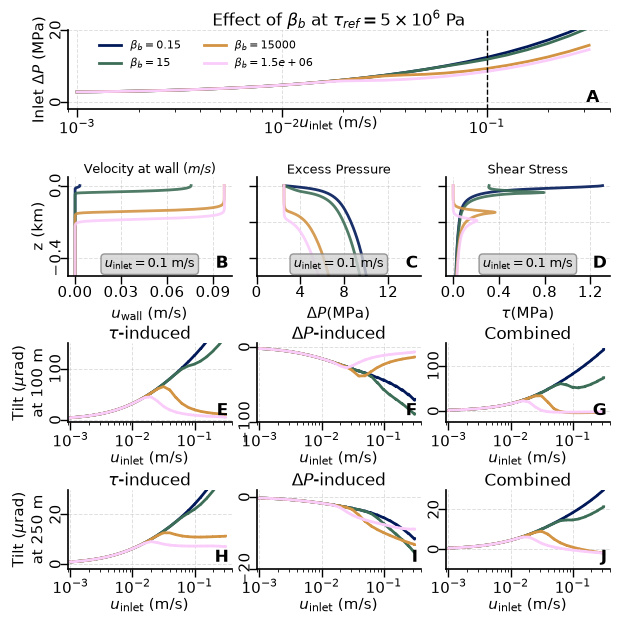

In [56]:
# =============================================================================
# EFFECT OF beta_b AT FIXED tau_ref = 5e6
#
# SAME GRID STRUCTURE AS ORIGINAL FIGURE:
#
#       A A A          row 0: chamber overpressure
#       B C D          row 1: depth profiles at U_in = 0.1
#       E F G          row 2: tilt at 100 m
#       H I J          row 3: tilt at 250 m
#
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from cmcrameri import cm as cmc


# =============================================================================
# GLOBAL PLOT SETTINGS
# =============================================================================

mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 12,
})


# =============================================================================
# DATA AND PLOTTING OPTIONS
# =============================================================================

variables = {
    'spf.U': r'$u_{\mathrm{wall}}$ (m/s)',
    'P_excess': r'$\Delta P$(MPa)',
    'spf.mu*spf.sr': r'$\tau$(MPa)',
}


fixed_tau_ref = 5e6
profile_velocity = 0.1


# Calculate excess pressure if required
if 'P_excess' not in df.columns:
    df = calculate_excess_pressure(df)


# =============================================================================
# SELECT PARAMETER VALUES
# =============================================================================

df_fixed = df[
    np.isclose(df['tau_ref'], fixed_tau_ref)
].copy()

df_ge_fixed = df_ge[
    np.isclose(df_ge['tau_ref'], fixed_tau_ref)
].copy()


beta_values = np.sort(
    df_fixed['beta_b'].dropna().unique()
)


# =============================================================================
# PARAMETER COLOURS
# =============================================================================

param_colours = [
    cmc.batlow(x)
    for x in np.linspace(0, 1, len(beta_values))
]

beta_to_colour = dict(
    zip(beta_values, param_colours)
)


# =============================================================================
# FIGURE AND GRIDSPEC
#
# EXACTLY AS ORIGINAL
# =============================================================================

fig = plt.figure(
    figsize=(7, 7)
)

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[0.8, 1.0, 0.8, 0.8],
    width_ratios=[1, 1, 1],
    hspace=0.8,
    wspace=0.15,
)


# Row 0
top_ax = fig.add_subplot(
    gs[0, :]
)


# Row 1
profile_axes = [
    fig.add_subplot(gs[1, i])
    for i in range(3)
]


# Row 2
tilt_100_axes = [
    fig.add_subplot(
        gs[2, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# Row 3
tilt_250_axes = [
    fig.add_subplot(
        gs[3, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# =============================================================================
# DEPTH PROFILES
#
# ONLY U_in = 0.1 m/s
# =============================================================================

for beta_b in beta_values:

    colour = beta_to_colour[beta_b]

    data_subset = df_fixed[
        np.isclose(df_fixed['beta_b'], beta_b)
        &
        np.isclose(df_fixed['U_in'], profile_velocity)
    ].sort_values('z')

    if data_subset.empty:
        continue

    depth = data_subset['z']

    for j, var in enumerate(variables):

        ax = profile_axes[j]

        if var not in data_subset.columns:
            continue


        if var in (
            'P_excess',
            'spf.mu*spf.sr',
        ):

            plot_vals = (
                data_subset[var]
                / 1e6
            )


        elif var == 'spf.U':

            plot_vals = (
                data_subset[var]
                
            )


        ax.plot(
            plot_vals,
            depth/1e3,
            color=colour,
            linewidth=2,
            alpha=0.9,
        )


# =============================================================================
# FORMAT DEPTH-PROFILE PANELS
# =============================================================================

for j, (var, xlabel) in enumerate(variables.items()):

    ax = profile_axes[j]

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylim(
        -0.500,
        0.050,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )

    if var == 'P_excess':

        ax.set_xlim(
            0,
            15,
        )

    if j == 0:

        ax.set_ylabel(
            'z (km)',
            labelpad=2,
        )
        ax.set_yticks([0,-0.4])

    else:

        ax.tick_params(
            axis='y',
            labelleft=False,
        )


profile_axes[0].set_title(
    r'Velocity at wall ($m/s$)',
    fontsize=9,
    pad=2,
)

profile_axes[1].set_title(
    'Excess Pressure',
    fontsize=9,
    pad=2,
)

profile_axes[2].set_title(
    'Shear Stress',
    fontsize=9,
    pad=2,
)


# =============================================================================
# CHAMBER OVERPRESSURE AT DEEPEST DEPTH
# =============================================================================

legend_handles = []


for beta_b in beta_values:

    colour = beta_to_colour[beta_b]

    df_param = df_fixed[
        np.isclose(df_fixed['beta_b'], beta_b)
        &
        (df_fixed['U_in'] >= 1e-3)
    ]

    if df_param.empty:
        continue


    deepest_idx = (
        df_param
        .groupby('U_in')['z']
        .idxmin()
    )


    df_deepest = (
        df_param
        .loc[deepest_idx]
        .sort_values('U_in')
    )


    top_ax.semilogx(
        df_deepest['U_in'],
        df_deepest['P_excess'] / 1e6,
        color=colour,
        linewidth=2,
        alpha=1,
    )


    legend_handles.append(
        plt.Line2D(
            [],
            [],
            color=colour,
            linewidth=2,
            label=rf'$\beta_b={beta_b:g}$',
        )
    )


# =============================================================================
# TILT DATA
# =============================================================================

param_to_column = {
    0: 0,
    2: 1,
    1: 2,
}


for beta_b in beta_values:

    colour = beta_to_colour[beta_b]

    df_beta_ge = df_ge_fixed[
        np.isclose(
            df_ge_fixed['beta_b'],
            beta_b
        )
    ]


    for param_def, column in param_to_column.items():

        df_param = df_beta_ge[
            df_beta_ge['param_def'] == param_def
        ]

        if df_param.empty:
            continue


        # ---------------------------------------------------------------------
        # TILT AT 100 m
        # ---------------------------------------------------------------------

        df_100 = (
            df_param[
                df_param['r'] == 100
            ]
            .sort_values('U_in')
        )

        if not df_100.empty:

            tilt_100_axes[column].semilogx(
                df_100['U_in'],
                df_100['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


        # ---------------------------------------------------------------------
        # TILT AT 250 m
        # ---------------------------------------------------------------------

        df_250 = (
            df_param[
                df_param['r'] == 250
            ]
            .sort_values('U_in')
        )

        if not df_250.empty:

            tilt_250_axes[column].semilogx(
                df_250['U_in'],
                df_250['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


# =============================================================================
# AXIS LABELS
# =============================================================================

velocity_label = (
    r'$u_{\mathrm{inlet}}$ (m/s)'
)


top_ax.set_xlabel(
    velocity_label,
    labelpad=-4,
)


for ax in (
    tilt_100_axes
    +
    tilt_250_axes
):

    ax.set_xlabel(
        velocity_label,
        labelpad=0,
    )


# =============================================================================
# CHAMBER-PRESSURE LABELS
# =============================================================================

top_ax.set_ylabel(
    r'Inlet $\Delta P$ (MPa)',
    labelpad=1,
)


top_ax.set_title(
    rf'Effect of $\beta_b$ at $\tau_{{ref}}=${format_latex_sci(fixed_tau_ref)} Pa',
    pad=1,
)


# =============================================================================
# TILT LABELS
# =============================================================================

tilt_100_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 100 m',
    labelpad=1,
)


tilt_250_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 250 m',
    labelpad=1,
)


tilt_titles = [
    r'$\tau$-induced',
    r'$\Delta P$-induced',
    'Combined',
]


for ax, title in zip(
    tilt_100_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


for ax, title in zip(
    tilt_250_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


# =============================================================================
# AXIS LIMITS
# =============================================================================

top_ax.set_xlim(
    9e-4,
    0.4,
)

top_ax.set_ylim(
    -2,
    20,
)


for ax in tilt_250_axes:

    if ax == tilt_250_axes[0]:
        ax.set_ylim(
            -2,
            30,
        )

    if ax == tilt_250_axes[1]:
        ax.set_ylim(
            -20,
            2,
        )

    if ax == tilt_250_axes[2]:
        ax.set_ylim(
            -10,
            30,
        )


for ax in tilt_100_axes:

    if ax == tilt_100_axes[0]:
        ax.set_ylim(
            -5,
            150,
        )

    if ax == tilt_100_axes[1]:
        ax.set_ylim(
            -100,
            5,
        )

    if ax == tilt_100_axes[2]:
        ax.set_ylim(
            -25,
            150,
        )


# =============================================================================
# COMMON AXIS STYLING
# =============================================================================

all_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for ax in all_axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1,
        pad=1,
    )

    ax.grid(
        True,
        alpha=0.4,
        linestyle='--',
        linewidth=0.7,
    )

    ax.spines['top'].set_visible(
        False
    )

    ax.spines['right'].set_visible(
        False
    )

    ax.spines['left'].set_linewidth(
        1.2
    )

    ax.spines['bottom'].set_linewidth(
        1.2
    )


# =============================================================================
# LEGEND
# =============================================================================

top_ax.legend(
    handles=legend_handles,
    fontsize=8,
    loc='upper left',
    bbox_to_anchor=(0.04, 1),
    frameon=False,
    ncol=2
)


# =============================================================================
# PANEL LETTERS
# =============================================================================

panel_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for i, ax in enumerate(panel_axes):

    panel_letter = chr(
        ord('A') + i
    )

    ax.text(
        0.98,
        0.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='none',
            edgecolor='none',
            alpha=0.7,
        ),
        zorder=10,
    )

    ax.tick_params(
        axis='y',
        labelrotation=90,
        pad=2,
    )

    for label in ax.get_yticklabels():

        label.set_horizontalalignment(
            'center'
        )

        label.set_verticalalignment(
            'center'
        )


# =============================================================================
# FINAL LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        0.85,
        1,
    ]
)
top_ax.xaxis.set_label_coords(0.5, -0.08)
top_ax.vlines(x=0.1, ymin=-2, ymax=20, color='k', linestyle='--', linewidth=1)
for ax in profile_axes:
    ax.text(
        0.5, 0.05,
        r'$u_{\mathrm{inlet}} = 0.1$ m/s',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=9,
        bbox=dict(
            boxstyle='round,pad=0.3',
            facecolor='lightgrey',
            edgecolor='grey',
            alpha=0.8,
        ),
    )

# save figure 
plt.savefig('../../output_plots/supplimentary/slip_supplementary_plot_beta_b.png', dpi=300, bbox_inches='tight')

plt.savefig('../../output_plots/supplimentary/slip_supplementary_plot_beta_b.pdf', dpi=300, bbox_inches='tight')
plt.show()

/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_2346/2750230347.py:665: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(


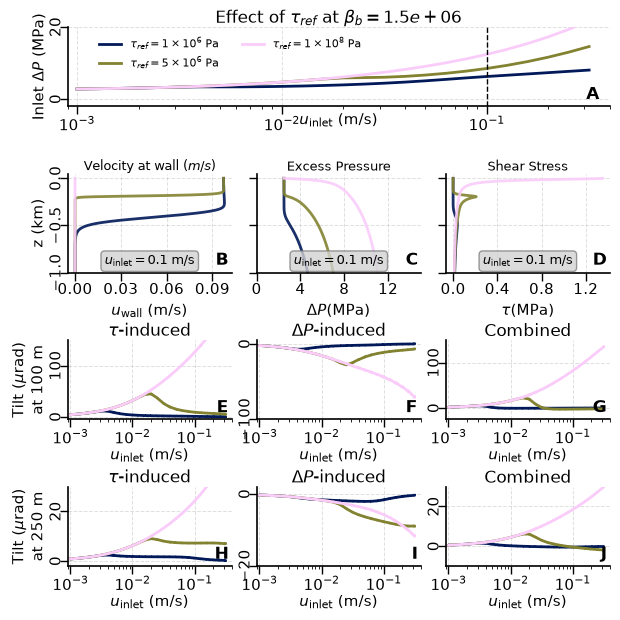

In [59]:
# =============================================================================
# EFFECT OF tau_ref AT FIXED beta_b = 15e5
#
# SAME GRID STRUCTURE AS beta_b FIGURE:
#
#       A A A          row 0: chamber overpressure
#       B C D          row 1: depth profiles at U_in = 0.1
#       E F G          row 2: tilt at 100 m
#       H I J          row 3: tilt at 250 m
#
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from cmcrameri import cm as cmc


# =============================================================================
# GLOBAL PLOT SETTINGS
# =============================================================================

mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 12,
})


# =============================================================================
# DATA AND PLOTTING OPTIONS
# =============================================================================

variables = {
    'spf.U': r'$u_{\mathrm{wall}}$ (m/s)',
    'P_excess': r'$\Delta P$(MPa)',
    'spf.mu*spf.sr': r'$\tau$(MPa)',
}


fixed_beta_b = 15e5
profile_velocity = 0.1


# Calculate excess pressure if required
if 'P_excess' not in df.columns:
    df = calculate_excess_pressure(df)


# =============================================================================
# SELECT PARAMETER VALUES
# =============================================================================

df_fixed = df[
    np.isclose(df['beta_b'], fixed_beta_b)
].copy()

df_ge_fixed = df_ge[
    np.isclose(df_ge['beta_b'], fixed_beta_b)
].copy()


tau_values = np.sort(
    df_fixed['tau_ref'].dropna().unique()
)


# =============================================================================
# PARAMETER COLOURS
# =============================================================================

param_colours = [
    cmc.batlow(x)
    for x in np.linspace(0, 1, len(tau_values))
]

tau_to_colour = dict(
    zip(tau_values, param_colours)
)


# =============================================================================
# FIGURE AND GRIDSPEC
# =============================================================================

fig = plt.figure(
    figsize=(7, 7)
)

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[0.8, 1.0, 0.8, 0.8],
    width_ratios=[1, 1, 1],
    hspace=0.8,
    wspace=0.15,
)


# Row 0
top_ax = fig.add_subplot(
    gs[0, :]
)


# Row 1
profile_axes = [
    fig.add_subplot(gs[1, i])
    for i in range(3)
]


# Row 2
tilt_100_axes = [
    fig.add_subplot(
        gs[2, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# Row 3
tilt_250_axes = [
    fig.add_subplot(
        gs[3, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# =============================================================================
# DEPTH PROFILES
#
# ONLY U_in = 0.1 m/s
# =============================================================================

for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    data_subset = df_fixed[
        np.isclose(df_fixed['tau_ref'], tau_ref)
        &
        np.isclose(df_fixed['U_in'], profile_velocity)
    ].sort_values('z')

    if data_subset.empty:
        continue

    depth = data_subset['z']

    for j, var in enumerate(variables):

        ax = profile_axes[j]

        if var not in data_subset.columns:
            continue


        # Pressure and shear stress: Pa -> MPa
        if var in (
            'P_excess',
            'spf.mu*spf.sr',
        ):

            plot_vals = (
                data_subset[var]
                / 1e6
            )


        # Wall velocity: plot actual velocity
        elif var == 'spf.U':

            plot_vals = (
                data_subset[var]
            )


        ax.plot(
            plot_vals,
            depth / 1e3,
            color=colour,
            linewidth=2,
            alpha=0.9,
        )


# =============================================================================
# FORMAT DEPTH-PROFILE PANELS
# =============================================================================

for j, (var, xlabel) in enumerate(variables.items()):

    ax = profile_axes[j]

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylim(
        -1.00,
        0.050,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )


    if var == 'P_excess':

        ax.set_xlim(
            0,
            15,
        )


    if j == 0:

        ax.set_ylabel(
            'z (km)',
            labelpad=2,
        )

   

    else:

        ax.tick_params(
            axis='y',
            labelleft=False,
        )


profile_axes[0].set_title(
    r'Velocity at wall ($m/s$)',
    fontsize=9,
    pad=2,
)

profile_axes[1].set_title(
    'Excess Pressure',
    fontsize=9,
    pad=2,
)

profile_axes[2].set_title(
    'Shear Stress',
    fontsize=9,
    pad=2,
)


# =============================================================================
# CHAMBER OVERPRESSURE AT DEEPEST DEPTH
# =============================================================================

legend_handles = []


for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    df_param = df_fixed[
        np.isclose(df_fixed['tau_ref'], tau_ref)
        &
        (df_fixed['U_in'] >= 1e-3)
    ]

    if df_param.empty:
        continue


    deepest_idx = (
        df_param
        .groupby('U_in')['z']
        .idxmin()
    )


    df_deepest = (
        df_param
        .loc[deepest_idx]
        .sort_values('U_in')
    )


    top_ax.semilogx(
        df_deepest['U_in'],
        df_deepest['P_excess'] / 1e6,
        color=colour,
        linewidth=2,
        alpha=1,
    )


    legend_handles.append(
        plt.Line2D(
            [],
            [],
            color=colour,
            linewidth=2,
            label=rf'$\tau_{{ref}}=${format_latex_sci(tau_ref)} Pa',
        )
    )


# =============================================================================
# TILT DATA
# =============================================================================

param_to_column = {
    0: 0,
    2: 1,
    1: 2,
}


for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    df_tau_ge = df_ge_fixed[
        np.isclose(
            df_ge_fixed['tau_ref'],
            tau_ref
        )
    ]


    for param_def, column in param_to_column.items():

        df_param = df_tau_ge[
            df_tau_ge['param_def'] == param_def
        ]

        if df_param.empty:
            continue


        # ---------------------------------------------------------------------
        # TILT AT 100 m
        # ---------------------------------------------------------------------

        df_100 = (
            df_param[
                df_param['r'] == 100
            ]
            .sort_values('U_in')
        )

        if not df_100.empty:

            tilt_100_axes[column].semilogx(
                df_100['U_in'],
                df_100['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


        # ---------------------------------------------------------------------
        # TILT AT 250 m
        # ---------------------------------------------------------------------

        df_250 = (
            df_param[
                df_param['r'] == 250
            ]
            .sort_values('U_in')
        )

        if not df_250.empty:

            tilt_250_axes[column].semilogx(
                df_250['U_in'],
                df_250['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


# =============================================================================
# AXIS LABELS
# =============================================================================

velocity_label = (
    r'$u_{\mathrm{inlet}}$ (m/s)'
)


top_ax.set_xlabel(
    velocity_label,
    labelpad=-4,
)


for ax in (
    tilt_100_axes
    +
    tilt_250_axes
):

    ax.set_xlabel(
        velocity_label,
        labelpad=0,
    )


# =============================================================================
# CHAMBER-PRESSURE LABELS
# =============================================================================

top_ax.set_ylabel(
    r'Inlet $\Delta P$ (MPa)',
    labelpad=1,
)


top_ax.set_title(
    rf'Effect of $\tau_{{ref}}$ at $\beta_b={fixed_beta_b:g}$',
    pad=1,
)


# =============================================================================
# TILT LABELS
# =============================================================================

tilt_100_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 100 m',
    labelpad=1,
)


tilt_250_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 250 m',
    labelpad=1,
)


tilt_titles = [
    r'$\tau$-induced',
    r'$\Delta P$-induced',
    'Combined',
]


for ax, title in zip(
    tilt_100_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


for ax, title in zip(
    tilt_250_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


# =============================================================================
# AXIS LIMITS
# =============================================================================

top_ax.set_xlim(
    9e-4,
    0.4,
)

top_ax.set_ylim(
    -2,
    20,
)


for ax in tilt_250_axes:

    if ax == tilt_250_axes[0]:
        ax.set_ylim(
            -2,
            30,
        )

    if ax == tilt_250_axes[1]:
        ax.set_ylim(
            -20,
            2,
        )

    if ax == tilt_250_axes[2]:
        ax.set_ylim(
            -10,
            30,
        )


for ax in tilt_100_axes:

    if ax == tilt_100_axes[0]:
        ax.set_ylim(
            -5,
            150,
        )

    if ax == tilt_100_axes[1]:
        ax.set_ylim(
            -100,
            5,
        )

    if ax == tilt_100_axes[2]:
        ax.set_ylim(
            -25,
            150,
        )


# =============================================================================
# COMMON AXIS STYLING
# =============================================================================

all_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for ax in all_axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1,
        pad=1,
    )

    ax.grid(
        True,
        alpha=0.4,
        linestyle='--',
        linewidth=0.7,
    )

    ax.spines['top'].set_visible(
        False
    )

    ax.spines['right'].set_visible(
        False
    )

    ax.spines['left'].set_linewidth(
        1.2
    )

    ax.spines['bottom'].set_linewidth(
        1.2
    )


# =============================================================================
# LEGEND
# =============================================================================

top_ax.legend(
    handles=legend_handles,
    fontsize=8,
    loc='upper left',
    bbox_to_anchor=(0.04, 1),
    frameon=False,
    ncol=2,
)


# =============================================================================
# PANEL LETTERS
# =============================================================================

panel_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for i, ax in enumerate(panel_axes):

    panel_letter = chr(
        ord('A') + i
    )

    ax.text(
        0.98,
        0.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='none',
            edgecolor='none',
            alpha=0.7,
        ),
        zorder=10,
    )

    ax.tick_params(
        axis='y',
        labelrotation=90,
        pad=2,
    )

    for label in ax.get_yticklabels():

        label.set_horizontalalignment(
            'center'
        )

        label.set_verticalalignment(
            'center'
        )


# =============================================================================
# FINAL LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        0.85,
        1,
    ]
)


# Move top-panel x label closer
top_ax.xaxis.set_label_coords(
    0.5,
    -0.08,
)


# Reference inlet velocity
top_ax.vlines(
    x=0.1,
    ymin=-2,
    ymax=20,
    color='k',
    linestyle='--',
    linewidth=1,
)


# Label fixed inlet velocity on each depth-profile panel
for ax in profile_axes:

    ax.text(
        0.5,
        0.05,
        r'$u_{\mathrm{inlet}} = 0.1$ m/s',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=9,
        bbox=dict(
            boxstyle='round,pad=0.3',
            facecolor='lightgrey',
            edgecolor='grey',
            alpha=0.8,
        ),
    )


# =============================================================================
# SAVE FIGURE
# =============================================================================

plt.savefig(
    '../../output_plots/supplimentary/slip_supplementary_plot_tau_ref.png',
    dpi=300,
    bbox_inches='tight',
)

plt.savefig(
    '../../output_plots/supplimentary/slip_supplementary_plot_tau_ref.pdf',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_2346/3225238925.py:622: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(


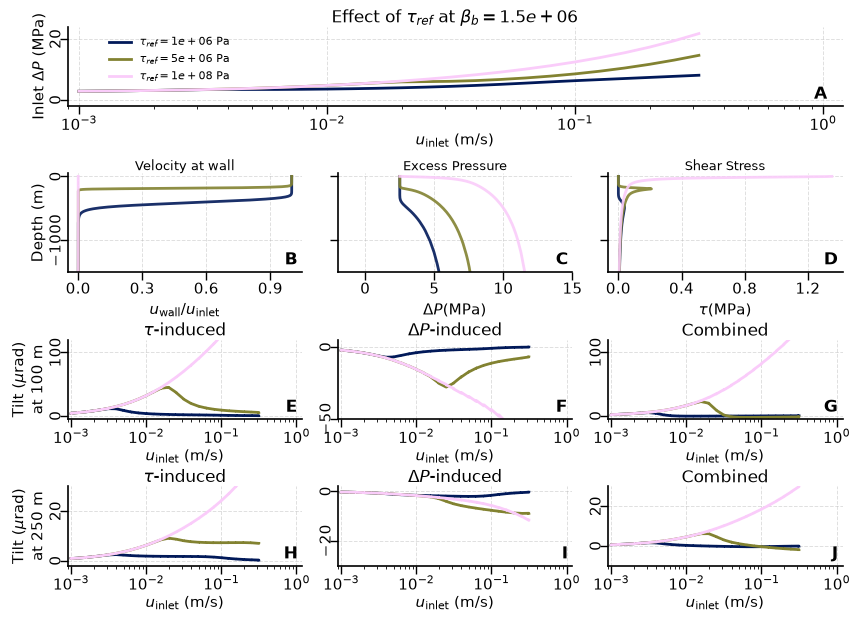

In [49]:
# =============================================================================
# EFFECT OF tau_ref AT FIXED beta_b = 15e5
#
# SAME GRID STRUCTURE AS ORIGINAL FIGURE:
#
#       A A A          row 0: chamber overpressure
#       B C D          row 1: depth profiles at U_in = 0.1
#       E F G          row 2: tilt at 100 m
#       H I J          row 3: tilt at 250 m
#
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from cmcrameri import cm as cmc


# =============================================================================
# GLOBAL PLOT SETTINGS
# =============================================================================

mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 12,
})


# =============================================================================
# DATA AND PLOTTING OPTIONS
# =============================================================================

variables = {
    'spf.U': r'$u_{\mathrm{wall}}/u_{\mathrm{inlet}}$',
    'P_excess': r'$\Delta P$(MPa)',
    'spf.mu*spf.sr': r'$\tau$(MPa)',
}


fixed_beta_b = 15e5
profile_velocity = 0.1


if 'P_excess' not in df.columns:
    df = calculate_excess_pressure(df)


# =============================================================================
# SELECT PARAMETER VALUES
# =============================================================================

df_fixed = df[
    np.isclose(df['beta_b'], fixed_beta_b)
].copy()

df_ge_fixed = df_ge[
    np.isclose(df_ge['beta_b'], fixed_beta_b)
].copy()


tau_values = np.sort(
    df_fixed['tau_ref'].dropna().unique()
)


# =============================================================================
# PARAMETER COLOURS
# =============================================================================

param_colours = [
    cmc.batlow(x)
    for x in np.linspace(0, 1, len(tau_values))
]

tau_to_colour = dict(
    zip(tau_values, param_colours)
)


# =============================================================================
# FIGURE AND GRIDSPEC
#
# EXACTLY AS ORIGINAL
# =============================================================================

fig = plt.figure(
    figsize=(10, 7)
)

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[0.8, 1.0, 0.8, 0.8],
    width_ratios=[1, 1, 1],
    hspace=0.8,
    wspace=0.15,
)


top_ax = fig.add_subplot(
    gs[0, :]
)


profile_axes = [
    fig.add_subplot(gs[1, i])
    for i in range(3)
]


tilt_100_axes = [
    fig.add_subplot(
        gs[2, i],
        sharex=top_ax,
    )
    for i in range(3)
]


tilt_250_axes = [
    fig.add_subplot(
        gs[3, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# =============================================================================
# DEPTH PROFILES
#
# ONLY U_in = 0.1 m/s
# =============================================================================

for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    data_subset = df_fixed[
        np.isclose(df_fixed['tau_ref'], tau_ref)
        &
        np.isclose(df_fixed['U_in'], profile_velocity)
    ].sort_values('z')

    if data_subset.empty:
        continue

    depth = data_subset['z']

    for j, var in enumerate(variables):

        ax = profile_axes[j]

        if var not in data_subset.columns:
            continue


        if var in (
            'P_excess',
            'spf.mu*spf.sr',
        ):

            plot_vals = (
                data_subset[var]
                / 1e6
            )


        elif var == 'spf.U':

            plot_vals = (
                data_subset[var]
                / data_subset['u_av']
            )


        ax.plot(
            plot_vals,
            depth,
            color=colour,
            linewidth=2,
            alpha=0.9,
        )


# =============================================================================
# FORMAT DEPTH-PROFILE PANELS
# =============================================================================

for j, (var, xlabel) in enumerate(variables.items()):

    ax = profile_axes[j]

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylim(
        -1500,
        50,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )

    if var == 'P_excess':

        ax.set_xlim(
            -2,
            15,
        )

    if j == 0:

        ax.set_ylabel(
            'Depth (m)',
            labelpad=2,
        )

    else:

        ax.tick_params(
            axis='y',
            labelleft=False,
        )


profile_axes[0].set_title(
    'Velocity at wall',
    fontsize=9,
    pad=2,
)

profile_axes[1].set_title(
    'Excess Pressure',
    fontsize=9,
    pad=2,
)

profile_axes[2].set_title(
    'Shear Stress',
    fontsize=9,
    pad=2,
)


# =============================================================================
# CHAMBER OVERPRESSURE AT DEEPEST DEPTH
# =============================================================================

legend_handles = []


for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    df_param = df_fixed[
        np.isclose(df_fixed['tau_ref'], tau_ref)
        &
        (df_fixed['U_in'] >= 1e-3)
    ]

    if df_param.empty:
        continue


    deepest_idx = (
        df_param
        .groupby('U_in')['z']
        .idxmin()
    )


    df_deepest = (
        df_param
        .loc[deepest_idx]
        .sort_values('U_in')
    )


    top_ax.semilogx(
        df_deepest['U_in'],
        df_deepest['P_excess'] / 1e6,
        color=colour,
        linewidth=2,
        alpha=1,
    )


    legend_handles.append(
        plt.Line2D(
            [],
            [],
            color=colour,
            linewidth=2,
            label=rf'$\tau_{{ref}}={tau_ref:.0e}$ Pa',
        )
    )


# =============================================================================
# TILT DATA
# =============================================================================

param_to_column = {
    0: 0,
    2: 1,
    1: 2,
}


for tau_ref in tau_values:

    colour = tau_to_colour[tau_ref]

    df_tau_ge = df_ge_fixed[
        np.isclose(
            df_ge_fixed['tau_ref'],
            tau_ref
        )
    ]


    for param_def, column in param_to_column.items():

        df_param = df_tau_ge[
            df_tau_ge['param_def'] == param_def
        ]

        if df_param.empty:
            continue


        # 100 m
        df_100 = (
            df_param[
                df_param['r'] == 100
            ]
            .sort_values('U_in')
        )

        if not df_100.empty:

            tilt_100_axes[column].semilogx(
                df_100['U_in'],
                df_100['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


        # 250 m
        df_250 = (
            df_param[
                df_param['r'] == 250
            ]
            .sort_values('U_in')
        )

        if not df_250.empty:

            tilt_250_axes[column].semilogx(
                df_250['U_in'],
                df_250['solid.RotrZ'] * 1e6,
                color=colour,
                linewidth=2,
                alpha=1,
            )


# =============================================================================
# AXIS LABELS
# =============================================================================

velocity_label = (
    r'$u_{\mathrm{inlet}}$ (m/s)'
)


top_ax.set_xlabel(
    velocity_label,
    labelpad=-1,
)


for ax in (
    tilt_100_axes
    +
    tilt_250_axes
):

    ax.set_xlabel(
        velocity_label,
        labelpad=1,
    )


# =============================================================================
# CHAMBER-PRESSURE LABELS
# =============================================================================

top_ax.set_ylabel(
    r'Inlet $\Delta P$ (MPa)',
    labelpad=1,
)


top_ax.set_title(
    rf'Effect of $\tau_{{ref}}$ at $\beta_b={fixed_beta_b:g}$',
    pad=1,
)


# =============================================================================
# TILT LABELS
# =============================================================================

tilt_100_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 100 m',
    labelpad=1,
)


tilt_250_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 250 m',
    labelpad=1,
)


tilt_titles = [
    r'$\tau$-induced',
    r'$\Delta P$-induced',
    'Combined',
]


for ax, title in zip(
    tilt_100_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


for ax, title in zip(
    tilt_250_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


# =============================================================================
# AXIS LIMITS
# =============================================================================

top_ax.set_xlim(
    9e-4,
    1.2,
)

top_ax.set_ylim(
    -2,
    24,
)


for ax in tilt_250_axes:

    if ax == tilt_250_axes[0]:
        ax.set_ylim(-2, 30)

    if ax == tilt_250_axes[1]:
        ax.set_ylim(-30, 2)

    if ax == tilt_250_axes[2]:
        ax.set_ylim(-10, 30)


for ax in tilt_100_axes:

    if ax == tilt_100_axes[0]:
        ax.set_ylim(-5, 120)

    if ax == tilt_100_axes[1]:
        ax.set_ylim(-50, 5)

    if ax == tilt_100_axes[2]:
        ax.set_ylim(-5, 120)


# =============================================================================
# COMMON AXIS STYLING
# =============================================================================

all_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for ax in all_axes:

    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1,
        pad=1,
    )

    ax.grid(
        True,
        alpha=0.4,
        linestyle='--',
        linewidth=0.7,
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)


# =============================================================================
# LEGEND
# =============================================================================

top_ax.legend(
    handles=legend_handles,
    fontsize=8,
    loc='upper left',
    bbox_to_anchor=(0.04, 1),
    frameon=False,
)


# =============================================================================
# PANEL LETTERS
# =============================================================================

panel_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for i, ax in enumerate(panel_axes):

    panel_letter = chr(
        ord('A') + i
    )

    ax.text(
        0.98,
        0.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='none',
            edgecolor='none',
            alpha=0.7,
        ),
        zorder=10,
    )

    ax.tick_params(
        axis='y',
        labelrotation=90,
        pad=2,
    )

    for label in ax.get_yticklabels():

        label.set_horizontalalignment(
            'center'
        )

        label.set_verticalalignment(
            'center'
        )


# =============================================================================
# FINAL LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        0.85,
        1,
    ]
)

plt.show()

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494700.0 to 101180000.0
Debug: P_excess range: -105300.0 to 19119000.0


KeyError: 'Slip'

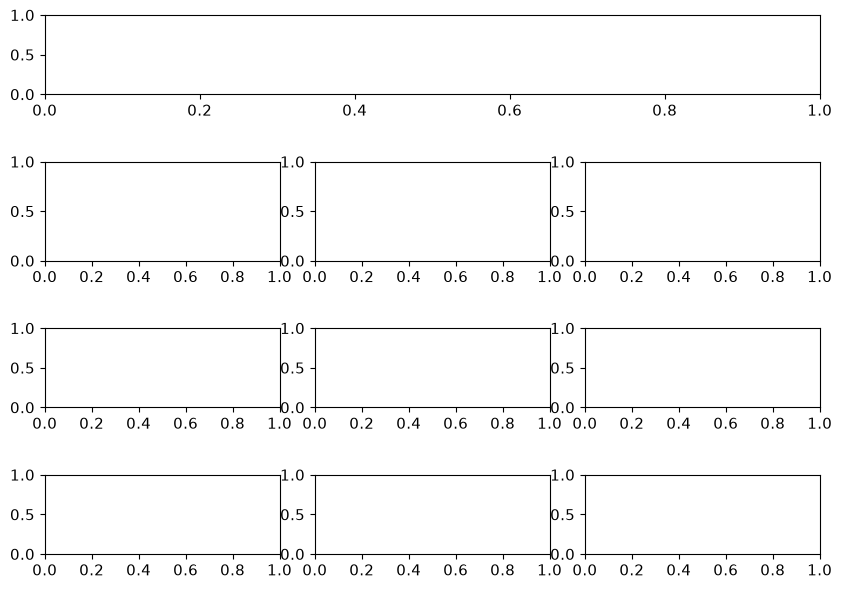

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from cmcrameri import cm as cmc


# =============================================================================
# GLOBAL PLOT SETTINGS
# =============================================================================

mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 12,
})


# =============================================================================
# DATA AND PLOTTING OPTIONS
# =============================================================================

# Variables shown as depth profiles.
variables = {
    'spf.U': r'$u_{\mathrm{wall}}/u_{\mathrm{inlet}}$',
    'P_excess': r'$\Delta P$(MPa)',
    'spf.mu*spf.sr': r'$\tau$(MPa)',
}

# Slip conditions.
#
# Friction Law:
#   - plotted in all panels
#
# No Slip:
#   - plotted as a dashed reference line in chamber-pressure and tilt panels
#   - NOT plotted in the depth-profile panels
slip_options = [
    'Friction Law',
    'No Slip',
]

# Calculate excess pressure before plotting.
df = calculate_excess_pressure(df)

# Use grey for both slip conditions.
# Linestyle will distinguish the two cases.
slip_to_color = {
    'Friction Law': 'grey',
    'No Slip': 'grey',
}

# Linestyle associated with each slip condition.
slip_to_linestyle = {
    'Friction Law': '-',
    'No Slip': '--',
}


# =============================================================================
# VELOCITIES AND COLOURS
# =============================================================================

# Convert velocities to NumPy array.
velocities = np.asarray(velocities)

# Only consider velocities >= 1e-3 m/s.
velocities = velocities[velocities >= 1e-3]

## Velocity used for depth-profile panels
profile_velocity = 0.1

# Keep these for the velocity markers in the other panels
selected_velocities = velocities[::2]

vel_colours = [
    cmc.batlow(x)
    for x in np.linspace(0, 1, len(selected_velocities))
]

velocity_to_colour = dict(
    zip(selected_velocities, vel_colours)
)

# =============================================================================
# FIGURE AND GRIDSPEC
#
# Grid layout:
#
#       A A A          row 0: chamber overpressure
#       B C D          row 1: depth profiles
#       E F G          row 2: tilt at 100 m
#       H I J          row 3: tilt at 250 m
#
# =============================================================================

fig = plt.figure(
    figsize=(10, 7)
)

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[0.8, 1.0, 0.8, 0.8],
    width_ratios=[1, 1, 1],
    hspace=0.8,
    wspace=0.15,
)


# -----------------------------------------------------------------------------
# Row 0: chamber overpressure
# -----------------------------------------------------------------------------

top_ax = fig.add_subplot(
    gs[0, :]
)


# -----------------------------------------------------------------------------
# Row 1: depth profiles
# -----------------------------------------------------------------------------

profile_axes = [
    fig.add_subplot(gs[1, i])
    for i in range(3)
]


# -----------------------------------------------------------------------------
# Row 2: tilt at 100 m
# -----------------------------------------------------------------------------

tilt_100_axes = [
    fig.add_subplot(
        gs[2, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# -----------------------------------------------------------------------------
# Row 3: tilt at 250 m
# -----------------------------------------------------------------------------

tilt_250_axes = [
    fig.add_subplot(
        gs[3, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# =============================================================================
# DEPTH PROFILES
#
# Only plot U_in = 0.1 m/s
# No Slip is deliberately excluded from these panels.
# =============================================================================

profile_velocity = 0.1

for slip in slip_options:

    # Do not plot No Slip in the depth-profile panels.
    if slip == 'No Slip':
        continue

    # Extract data for this slip condition and U_in = 0.1 m/s.
    data_subset = df[
        (df['Slip'] == slip)
        &
        np.isclose(df['U_in'], profile_velocity)
    ].sort_values('z')

    if data_subset.empty:
        continue

    depth = data_subset['z']

    for j, var in enumerate(variables):

        ax = profile_axes[j]

        # Skip if the variable is absent from the dataframe.
        if var not in data_subset.columns:
            continue

        # ---------------------------------------------------------
        # Pressure and shear stress:
        # convert Pa -> MPa
        # ---------------------------------------------------------
        if var in (
            'P_excess',
            'spf.mu*spf.sr',
        ):

            plot_vals = (
                data_subset[var]
                / 1e6
            )

        # ---------------------------------------------------------
        # Wall velocity:
        # normalise by average/inlet velocity
        # ---------------------------------------------------------
        elif var == 'spf.U':

            plot_vals = (
                data_subset[var]
                / data_subset['u_av']
            )

        # ---------------------------------------------------------
        # Plot depth profile at U_in = 0.1 m/s
        # ---------------------------------------------------------
        ax.plot(
            plot_vals,
            depth,
            color='grey',
            linewidth=2,
            alpha=0.9,
        )
# =============================================================================
# FORMAT DEPTH-PROFILE PANELS
# =============================================================================

for j, (var, xlabel) in enumerate(variables.items()):

    ax = profile_axes[j]

    # Axis label.
    ax.set_xlabel(
        xlabel
    )

    # Depth limits.
    ax.set_ylim(
        -1500,
        50,
    )

    # Limit number of x ticks.
    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )

    # Specific pressure-axis limits.
    if var == 'P_excess':

        ax.set_xlim(
            -2,
            15,
        )

    # Only show depth axis on left-most plot.
    if j == 0:

        ax.set_ylabel(
            'Depth (m)',
            labelpad=2,
        )

    else:

        ax.tick_params(
            axis='y',
            labelleft=False,
        )


# Titles for depth-profile panels.
profile_axes[0].set_title(
    'Velocity at wall',
    fontsize=9,
    pad=2,
)

profile_axes[1].set_title(
    'Excess Pressure',
    fontsize=9,
    pad=2,
)

profile_axes[2].set_title(
    'Shear Stress',
    fontsize=9,
    pad=2,
)


# =============================================================================
# CHAMBER OVERPRESSURE AT THE DEEPEST DEPTH
#
# Friction Law = solid grey
# No Slip      = dashed grey
#
# Coloured velocity markers are only applied to Friction Law.
# =============================================================================

legend_handles = []


for slip in slip_options:

    # Extract relevant data.
    df_slip = df[
        (df['Slip'] == slip)
        &
        (df['U_in'] >= 1e-3)
    ]

    # Skip if no data exist.
    if df_slip.empty:
        continue

    # Get plotting style.
    line_colour = slip_to_color[slip]
    linestyle = slip_to_linestyle[slip]

    # -------------------------------------------------------------------------
    # Find the deepest z for each inlet velocity.
    # -------------------------------------------------------------------------

    deepest_idx = (
        df_slip
        .groupby('U_in')['z']
        .idxmin()
    )

    # Rows corresponding to deepest depth.
    df_deepest = (
        df_slip
        .loc[deepest_idx]
        .sort_values('U_in')
    )

    # Extract velocity.
    velocities_deepest = (
        df_deepest['U_in']
        .to_numpy()
    )

    # Extract P_excess and convert Pa -> MPa.
    p_excess_deepest = (
        df_deepest['P_excess']
        .to_numpy()
        / 1e6
    )

    # -------------------------------------------------------------------------
    # Plot continuous pressure curve.
    # -------------------------------------------------------------------------

    top_ax.semilogx(
        velocities_deepest,
        p_excess_deepest,
        color=line_colour,
        linestyle=linestyle,
        linewidth=2,
        alpha=1,
    )

    # -------------------------------------------------------------------------
    # Add coloured velocity markers only for Friction Law.
    # -------------------------------------------------------------------------

    if slip != 'No Slip':

        for velocity in selected_velocities:

            point = df_deepest[
                df_deepest['U_in'] == velocity
            ]

            if point.empty:
                continue

            p_excess = point['P_excess'].iloc[0] / 1e6

            # Exactly the same lookup used in the depth-profile panels.
            colour = velocity_to_colour[velocity]

            top_ax.semilogx(
                velocity,
                p_excess,
                marker='o',
                markersize=10,
                color=colour,
                linewidth=0,
                zorder=15,
            )

    # -------------------------------------------------------------------------
    # Legend handle.
    # -------------------------------------------------------------------------
    if slip == 'Friction Law':
        label = 'Slip Law'
    else:
        label = slip
    legend_handles.append(
        plt.Line2D(
            [],
            [],
            color=line_colour,
            linestyle=linestyle,
            linewidth=2,
            label=label,
        )
    )


# =============================================================================
# TILT DATA
#
# param_def -> column
#
#   0 -> shear stress only -> tau
#   2 -> pressure only     -> Delta P
#   1 -> combined          -> Combined
#
# Friction Law = solid
# No Slip      = dashed
# =============================================================================

param_to_column = {
    0: 0,
    2: 1,
    1: 2,
}


for slip in slip_options:

    # Get line appearance.
    line_colour = slip_to_color[slip]
    linestyle = slip_to_linestyle[slip]

    for param_def, column in param_to_column.items():

        # ---------------------------------------------------------------------
        # Filter data for slip condition and deformation source.
        # ---------------------------------------------------------------------

        df_param = df_ge[
            (df_ge['Slip'] == slip)
            &
            (df_ge['param_def'] == param_def)
        ]

        if df_param.empty:
            continue


        # =====================================================================
        # TILT AT 100 m
        # =====================================================================

        df_100 = (
            df_param[
                df_param['r'] == 100
            ]
            .sort_values('U_in')
        )

        if not df_100.empty:

            tilt_100_axes[column].semilogx(
                df_100['U_in'],
                df_100['solid.RotrZ'] * 1e6,
                color=line_colour,
                linestyle=linestyle,
                linewidth=2,
                alpha=1,
            )


        # =====================================================================
        # TILT AT 250 m
        # =====================================================================

        df_250 = (
            df_param[
                df_param['r'] == 250
            ]
            .sort_values('U_in')
        )

        if not df_250.empty:

            tilt_250_axes[column].semilogx(
                df_250['U_in'],
                df_250['solid.RotrZ'] * 1e6,
                color=line_colour,
                linestyle=linestyle,
                linewidth=2,
                alpha=1,
            )


# =============================================================================
# AXIS LABELS
# =============================================================================

velocity_label = (
    r'$u_{\mathrm{inlet}}$ (m/s)'
)


# Chamber-pressure x-axis.
top_ax.set_xlabel(
    velocity_label,
    labelpad=0,
)


# Tilt x-axes.
for ax in (
    tilt_100_axes
    +
    tilt_250_axes
):

    ax.set_xlabel(
        velocity_label,
        labelpad=1,
    )


# =============================================================================
# CHAMBER-PRESSURE LABELS
# =============================================================================

top_ax.set_ylabel(
    r'Inlet $\Delta P$ (MPa)',
    labelpad=1,
)

top_ax.set_title(
    'Effect of Slip at Conduit Wall',
    pad=1,
)


# =============================================================================
# TILT LABELS
# =============================================================================

tilt_100_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 100 m',
    labelpad=1,
)

tilt_250_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 250 m',
    labelpad=1,
)


# Titles describing deformation source.
tilt_titles = [
    r'$\tau$-induced',
    r'$\Delta P$-induced',
    'Combined',
]


for ax, title in zip(
    tilt_100_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


for ax, title in zip(
    tilt_250_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


# =============================================================================
# AXIS LIMITS
# =============================================================================

# Chamber pressure.
top_ax.set_xlim(
    9e-4,
    1.2,
)

top_ax.set_ylim(
    -2,
    24,
)


# Tilt at 100 m.



# Tilt at 250 m.
for ax in tilt_250_axes:
    if ax == tilt_250_axes[0]:
        ax.set_ylim(
            -2,
            30,
        )
    if ax == tilt_250_axes[1]:
        ax.set_ylim(
            -30,
            2,
        )
    if ax == tilt_250_axes[2]:
        ax.set_ylim(
            -10,
            30,
        )
for ax in tilt_100_axes:
    if ax == tilt_100_axes[0]:
        ax.set_ylim(
            -5,
            120,
        )
    if ax == tilt_100_axes[1]:
        ax.set_ylim(
            -50,
            5,
        )
    if ax == tilt_100_axes[2]:
        ax.set_ylim(
            -5,
            120,
        )

# =============================================================================
# REFERENCE VELOCITY
# =============================================================================

# top_ax.axvline(
#     0.1,
#     color='blue',
#     linestyle='--',
#     linewidth=1,
#     alpha=0.7,
# )


# =============================================================================
# COMMON AXIS STYLING
# =============================================================================

# All axes in their GridSpec reading order.
all_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for ax in all_axes:

    # Tick style.
    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1,
        pad=1,
    )

    # Grid.
    ax.grid(
        True,
        alpha=0.4,
        linestyle='--',
        linewidth=0.7,
    )

    # Remove top/right spines.
    ax.spines['top'].set_visible(
        False
    )

    ax.spines['right'].set_visible(
        False
    )

    # Set remaining spine widths.
    ax.spines['left'].set_linewidth(
        1.2
    )

    ax.spines['bottom'].set_linewidth(
        1.2
    )


# =============================================================================
# LEGEND
#
# Solid grey  = Friction Law
# Dashed grey = No Slip
# =============================================================================

top_ax.legend(
    handles=legend_handles,
    fontsize=8,
    loc='upper left',
    bbox_to_anchor=(0.04, 1),
    frameon=False,
)


# =============================================================================
# PANEL LETTERS
#
# GridSpec reading order:
#
#       A
#     B C D
#     E F G
#     H I J
#
# All panel letters are placed in the bottom-right corner.
# =============================================================================

panel_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for i, ax in enumerate(panel_axes):

    panel_letter = chr(
        ord('A') + i
    )

    ax.text(
        0.98,
        0.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='none',
            edgecolor='none',
            alpha=0.7,
        ),
        zorder=10,
    )
    
    ax.tick_params(axis='y', labelrotation=90,pad=2)
    for label in ax.get_yticklabels():
        label.set_horizontalalignment('center')
        label.set_verticalalignment('center')

# =============================================================================
# FINAL LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        0.85,
        1,
    ]
)


# =============================================================================
# OPTIONAL: SAVE FIGURE
# =============================================================================
fig.savefig('../../output_plots/Supplimentary_slip_models_figure.pdf', dpi=300)
plt.show()